<a href="https://colab.research.google.com/github/psept77-star/Disease-Prediction/blob/main/Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Step 1 - Import liabraries
import numpy as np
import pandas as pd
from scipy.stats import mode
import matplotlib.pyplot as plt
import seaborn as sns
from statistics import mode
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from imblearn.over_sampling import RandomOverSampler
%matplotlib inline

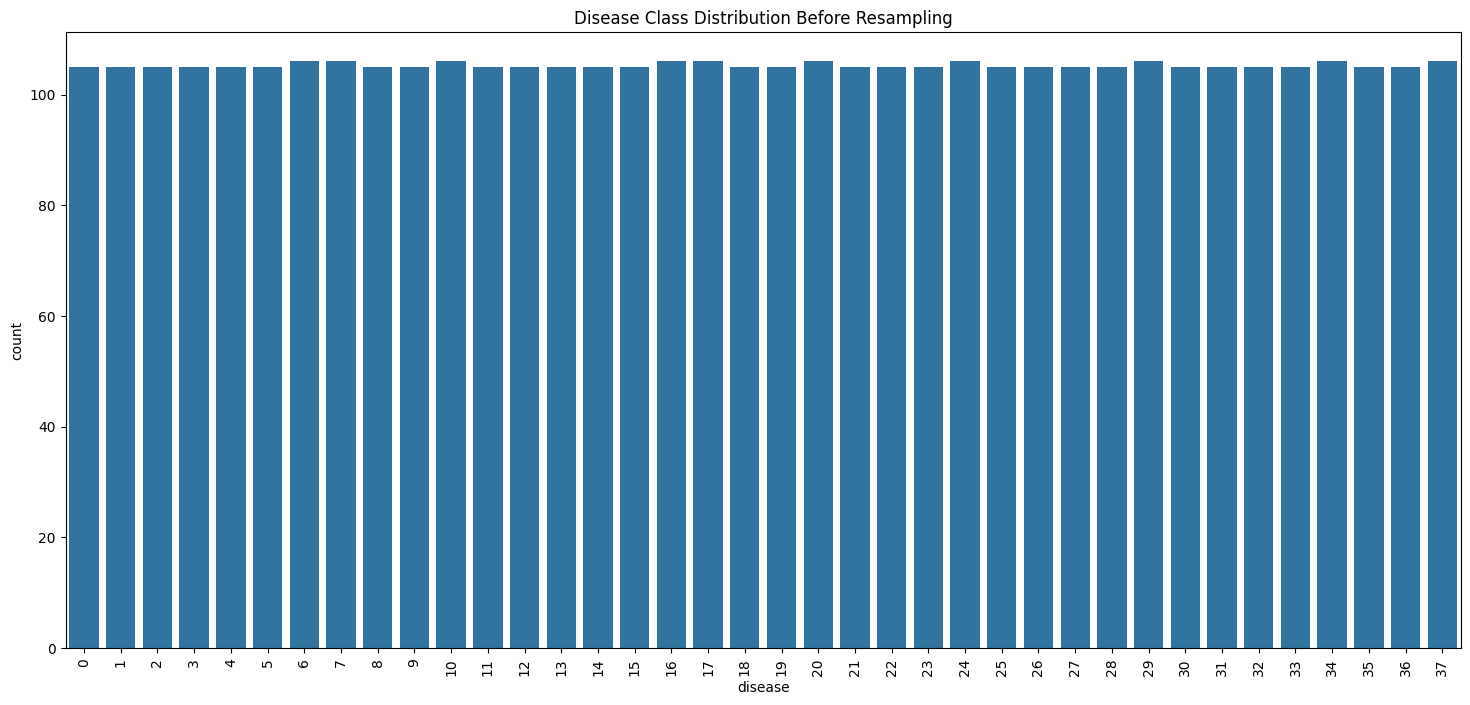

In [2]:
# Step 2 Reading the dataset
data = pd.read_csv('/content/sample_data/disease_dataset_4000.csv')

encoder = LabelEncoder()
data['disease'] = encoder.fit_transform(data['disease'])

x = data.iloc[:, :-1]
y = data.iloc[:, -1]

plt.figure(figsize=(18, 8))
sns.countplot(x=y)
plt.title("Disease Class Distribution Before Resampling")
plt.xticks(rotation=90)
plt.show()
ros = RandomOverSampler(random_state=42)
x_resampled, y_resampled = ros.fit_resample(x, y)

In [3]:
if 'gender' in x_resampled.columns:
    le = LabelEncoder()
    x_resampled['gender'] = le.fit_transform(x_resampled['gender'])

x_resampled = x_resampled.fillna(0)

if len(y_resampled.shape) > 1:
  y_resampled = y_resampled.values.ravel()

models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC()
}

cv_scoring = 'accuracy'

stratified_kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

for model_name, model in models.items():
    try:
        scores = cross_val_score(
                 model,
                 x_resampled,
                 y_resampled,
                 cv=stratified_kfold,
                 scoring=cv_scoring,
                 n_jobs=-1,
                 error_score='raise'
                 )
        print("=" * 50)
        print(f"Model:",model_name)
        print(f"Scores: {scores}")
        print(f"Mean Accuracy: {scores.mean():.4f}")
    except Exception as e:
      print("=" * 50)
      print(f"Model: {model_name} Failed with error")
      print(e)

Model: Decision Tree
Scores: [0.18858561 0.20099256 0.18858561 0.16129032 0.17369727 0.191067
 0.19602978 0.17866005 0.17412935 0.16666667]
Mean Accuracy: 0.1820
Model: Random Forest
Scores: [0.18858561 0.21091811 0.18114144 0.16129032 0.18362283 0.17617866
 0.21836228 0.18114144 0.18656716 0.17412935]
Mean Accuracy: 0.1862
Model: Naive Bayes
Scores: [0.20099256 0.25558313 0.18858561 0.20347395 0.20099256 0.20347395
 0.20595533 0.22580645 0.2039801  0.21890547]
Mean Accuracy: 0.2108
Model: SVM
Scores: [0.2133995  0.22580645 0.22580645 0.21091811 0.23076923 0.21836228
 0.2133995  0.21588089 0.20149254 0.24626866]
Mean Accuracy: 0.2202


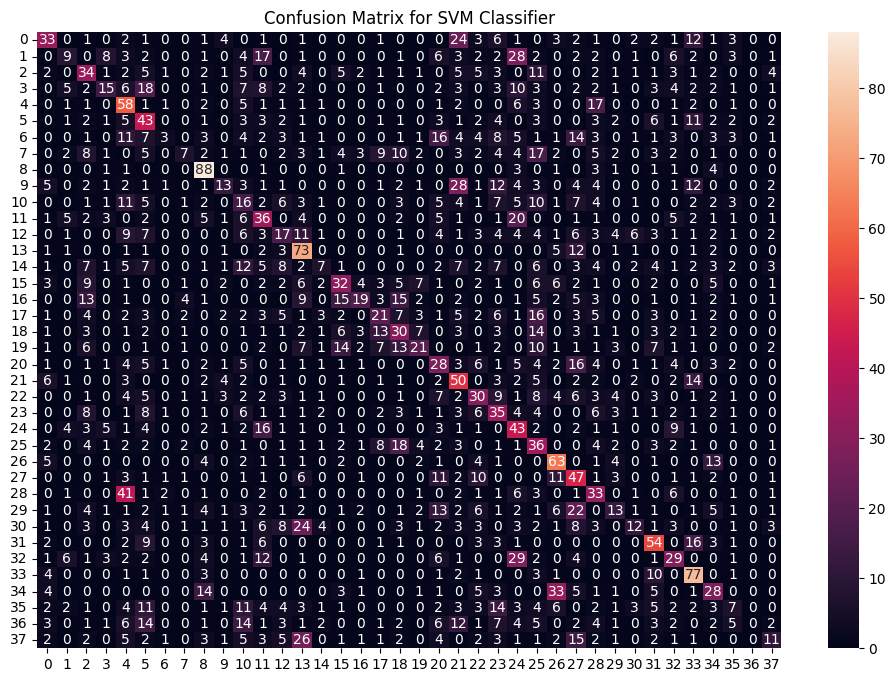

SVM Accuracy: 29.07%


In [4]:
# Step 4 : Training Individual Models and Generating Confusion Matrices
# Support Vector Classifier
svm_model = SVC()
svm_model.fit(x_resampled, y_resampled)
svm_preds = svm_model.predict(x_resampled)

cf_matrix_svm = confusion_matrix(y_resampled, svm_preds)
plt.figure(figsize=(12,8))
sns.heatmap(cf_matrix_svm, annot=True, fmt="d")
plt.title("Confusion Matrix for SVM Classifier")
plt.show()

print(f"SVM Accuracy: {accuracy_score(y_resampled, svm_preds) * 100:.2f}%")


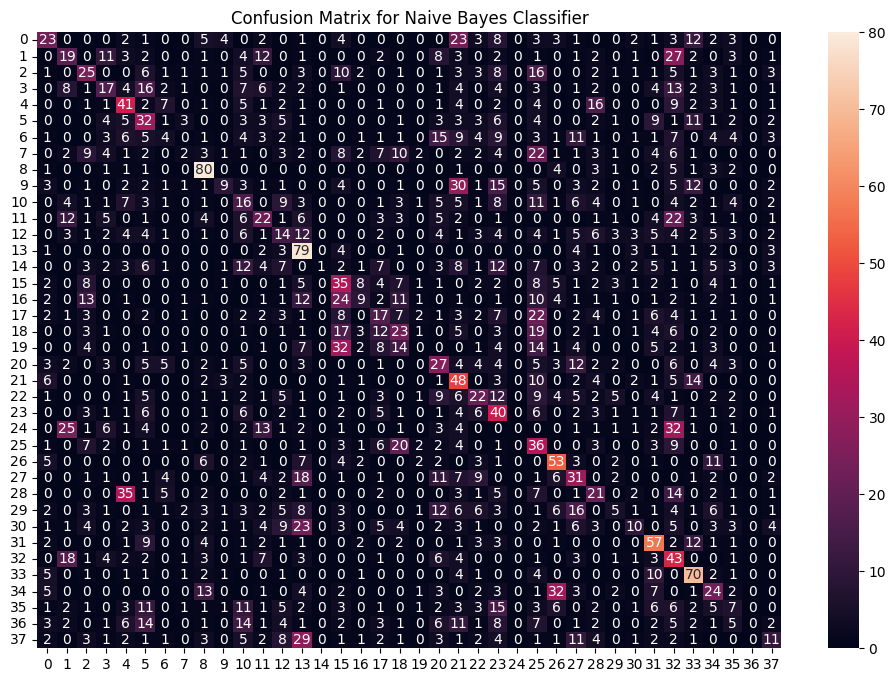

Naive Bayes Accuracy: 24.16%


In [5]:
# Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(x_resampled, y_resampled)
nb_preds = nb_model.predict(x_resampled)

cf_matrix_nb =  confusion_matrix(y_resampled, nb_preds)
plt.figure(figsize=(12, 8))
sns.heatmap(cf_matrix_nb, annot=True, fmt="d")
plt.title("Confusion Matrix for Naive Bayes Classifier")
plt.show()

print(f"Naive Bayes Accuracy: {accuracy_score(y_resampled, nb_preds) * 100:.2f}%")

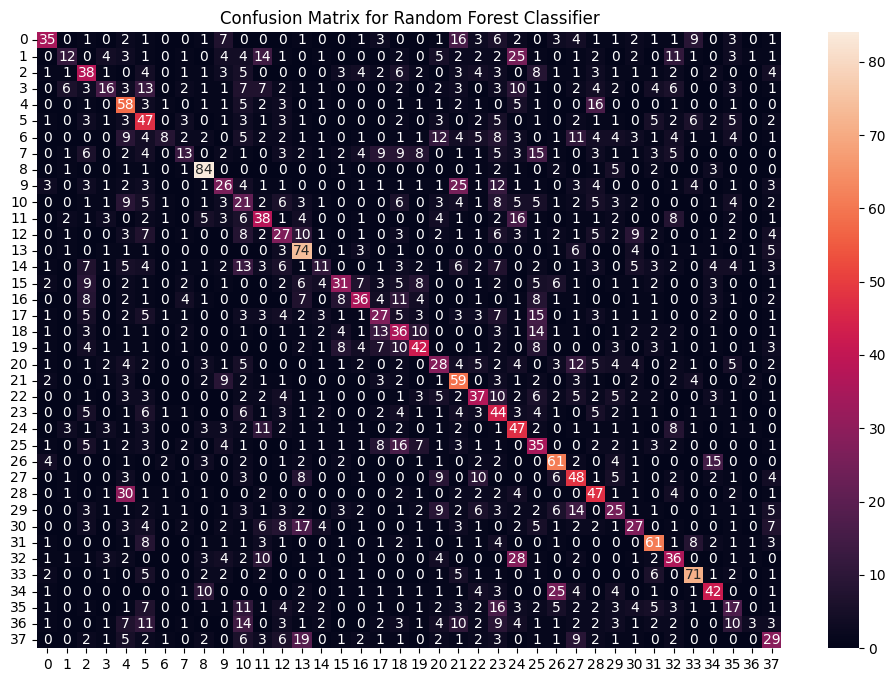

Random Forest Accuracy: 34.68%


In [6]:
# Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(x_resampled, y_resampled)
rf_preds = rf_model.predict(x_resampled)

cf_matrix_rf = confusion_matrix(y_resampled, rf_preds)
plt.figure(figsize=(12, 8))
sns.heatmap(cf_matrix_rf, annot=True, fmt="d")
plt.title("Confusion Matrix for Random Forest Classifier")
plt.show()

print(f"Random Forest Accuracy: {accuracy_score(y_resampled, rf_preds) * 100:.2f}%")


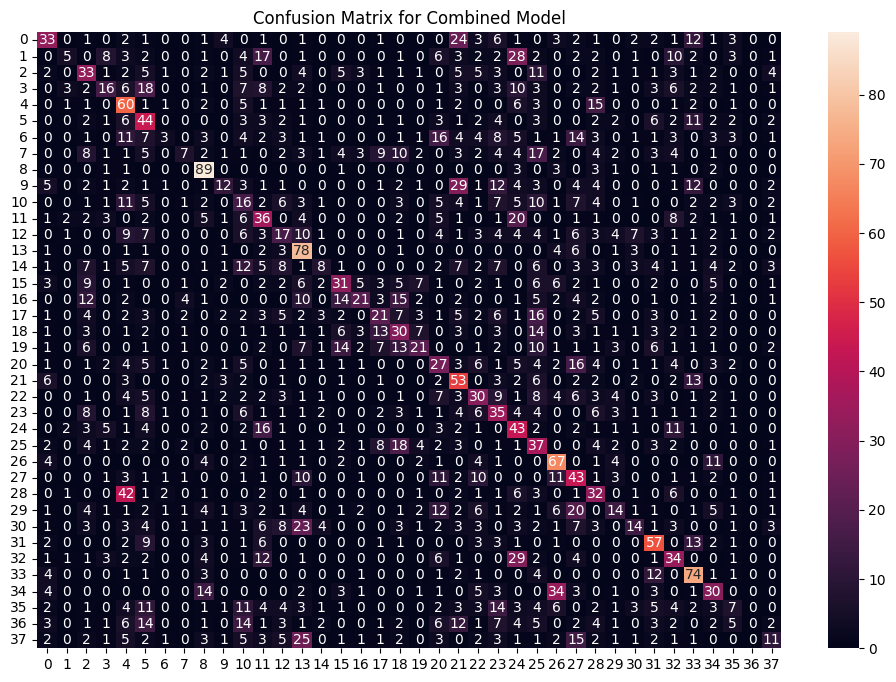

Combined Model Accuracy: 29.52%


In [8]:
# Combining predictions for Robustness
from statistics import mode
final_preds = [mode([i, j, k]) for i, j , k in zip(svm_preds, nb_preds, rf_preds)]
cf_matrix_combined = confusion_matrix(y_resampled, final_preds)
plt.figure(figsize=(12, 8))
sns.heatmap(cf_matrix_combined, annot=True, fmt="d")
plt.title("Confusion Matrix for Combined Model")
plt.show()

print(f"Combined Model Accuracy: {accuracy_score(y_resampled, final_preds) * 100:.2f}%")

In [9]:
# Step 6: Creating Prediction Function
symptoms = x.columns.values

symptom_index = {symptom: idx for idx, symptom in enumerate(symptoms)}
#symptom_index = {symptoms: idx for idx, symtom in enumerate(symptoms)}
def predictDisease(input_symptoms):
    input_symptoms = input_symptoms.split(",")
    input_data = [0] * len(symptom_index)

    for symptom in input_symptoms:
        symptom = symptom.strip()
        if symptom in symptom_index:
            input_data[symptom_index[symptom]] = 1

    input_df = pd.DataFrame([input_data], columns=symptoms)

    rf_pred = encoder.classes_[rf_model.predict(input_df)[0]]
    nb_preds = encoder.classes_[nb_model.predict(input_df)[0]]
    svm_pred = encoder.classes_[svm_model.predict(input_df)[0]]

    final_pred = mode([rf_pred, nb_preds, svm_pred])

    return {
        "Random Forest Prediction": rf_pred,
        "Naive Bayes Prediction": nb_preds,
        "SVM Prediction": svm_pred,
        "Final Prediction": final_pred
    }
print(predictDisease("skin_rash, fever, headache"))

{'Random Forest Prediction': 'Dengue', 'Naive Bayes Prediction': 'Dengue', 'SVM Prediction': 'Dengue', 'Final Prediction': 'Dengue'}


### Interactive Disease Predictor (Best Model: SVM)


In [12]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Get list of unique symptoms
symptom_list = sorted(list(symptoms))

# Create a multi-select widget
symptom_select = widgets.SelectMultiple(
    options=symptom_list,
    description='Symptoms:',
    disabled=False,
    layout=widgets.Layout(width='50%', height='180px')
)

# Create a predict button
predict_button = widgets.Button(
    description='Predict Disease',
    disabled=False,
    button_style='success',
    tooltip='Click to predict based on selected symptoms',
    icon='check'
)

# Output widget for predictions
output = widgets.Output()

def on_button_clicked(b):
    with output:
        clear_output()
        selected = list(symptom_select.value)
        if not selected:
            print("Please select at least one symptom!")
            return

        # Prepare the input data frame
        input_data = [0] * len(symptom_index)
        for s in selected:
            if s in symptom_index:
                input_data[symptom_index[s]] = 1

        input_df = pd.DataFrame([input_data], columns=symptoms)

        # Predict using SVM (best performing model based on CV)
        svm_encoded_pred = svm_model.predict(input_df)[0]
        predicted_disease = encoder.classes_[svm_encoded_pred]

        print(f"Selected Symptoms: {', '.join(selected)}")
        print("-" * 50)
        print(f"Predicted Disease (SVM Model): {predicted_disease}")

predict_button.on_click(on_button_clicked)

# Display widgets
display(widgets.VBox([symptom_select, predict_button, output]))